# AI-Based Math Concet Gap Diagnosis App - Colab Notebook

This Colab-ready notebook builds a **prototype pipeline** for an AI app that Minglang is the author and Qingyang is the advisor:

- generates **synthetic student-problem interaction data**
- identifies the **most likely missing math concepts** behid incorrect answers
- trains **machine learning** and **deep learning** models for concept-gap prediction
- demonstrates a lightweight **reinforcement learning & adaptive review** module
- prepares the core logic that can later be pakcaged into a **web app** and **IOS-style Apple app backend**

## Target product idea
For each student and each incorrectly answered math problem, the app will estimate:

1. the **first most missing math concept**
2. the **second most missing math concept**
3. additional missing concepts to review

The long-term goal is to help a student review the right concepts and then solve the current and similar problems correctly.

## Notebook structure
1. Setup
2. Synthetic data generation
3. Problem bank and concpet graph
4. Student knowledge simulation
5. Interaction simulation
6. Feature engineering
7. Machine learning baseline
8. Deep learning model
9. Reinforcement learning style adaptive review demo
10. Export-ready objects for later app packaging

In [ ]:
# Core imports
import numpy as np
import pandas as pd
import random
from collections import defaultdict, Counter
from dataclasses import dataclass
from typing import List, Dict, Tuple
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MultiLabelBinarizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, top_k_accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.linear_model import LogisticRegression

In [ ]:
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    TF_AVAILABLE = True
    tf.random.set_seed(SEED)
except Exception as e:
    TF_AVAILABLE = False
    print('Tensorflow not available:', e)

print('TensorFlow available:', TF_AVAILABLE)


TensorFlow available: True


## 1. Define the math concepts

We create a concept graph. A problem may directly test one or more concepts, but success may also depend on prerequiresite concepts.

Example:
- `fractions_addition` may depend on `integer_arithmetic`
- `linear_equations` may depend on `algebraic_simplification`
- `quadratic_equations` may depend on `linear_equations`

In [ ]:
CONCEPTS = [
    'integer_arithmetic',
    'fractions',
    'decimals',
    'ratios_proportions',
    'percentages',
    'algebraic_simplification',
    'linear_equations',
    'exponents',
    'polynomials',
    'quadratic_equations',
    'geometry_area',
    'geometry_volume',
    'probability_basics',
    'data_interpretation'
]

PREREQS = {
    'integer_arithmetic': [],
    'fractions': ['integer_arithmetic'],
    'decimals': ['integer_arithmetic'],
    'ratios_proportions': ['fractions', 'decimals'],
    'percentages': ['fractions', 'decimals', 'ratios_proportions'],
    'algebraic_simplification': ['integer_arithmetic'],
    'linear_equations': ['algebraic_simplification'],
    'systems_of_equations': ['linear_equations'],
    'exponents': ['integer_arithmetic'],
    'polynomials': ['algebraic_simplification', 'exponents'],
    'quadratic_equations': ['linear_equations', 'polynomials'],
    'geometry_area': ['integer_arithmetic', 'fractions'],
    'geometry_volume': ['geometry_area'],
    'probability_basics': ['fractions', 'ratios_proportions'],
    'data_interpretation': ['integer_arithmetic', 'percentages']
}

concept_to_idx = {c: i for i, c in enumerate(CONCEPTS)}
len(CONCEPTS)

14

## 2. Create a synthetic problem bank

Each problem has:
- problem id
- grade band
- difficulty
- primary tested concepts
- all required concepts = primary concepts + prerequisite chain

In [ ]:
def get_full_prereqs(concept, prereq_map):
    seen = set()
    stack = list(prereq_map.get(concept, []))
    while stack:
        c = stack.pop()
        if c not in seen:
            seen.add(c)
            stack.extend(prereq_map.get(c, []))
    return list(seen)

def build_problem_bank(num_problems=600):
    rows = []
    for pid in range(num_problems):
        n_primary = np.random.choice([1, 2], p=[0.72, 0.28])
        primary = random.sample(CONCEPTS, n_primary)
        all_required = set(primary)
        for c in primary:
            all_required.update(get_full_prereqs(c, PREREQS))
        difficulty = np.clip(
            0.8 + 0.35*len(all_required) + np.random.normal(0, 0.25),
            0.5, 4.5
        )
        grade_band = np.random.choice(
            ['elementary', 'middle', 'high'],
            p=[0.25, 0.45, 0.30]
        )
        rows.append({
            'problem_id': f'P{pid:04d}',
            'grade_band': grade_band,
            'difficulty': round(float(difficulty), 2),
            'primary_concepts': tuple(sorted(primary)),
            'required_concepts': tuple(sorted(all_required))
        })
    return pd.DataFrame(rows)

problem_bank = build_problem_bank()
problem_bank.head()


,problem_id,grade_band,difficulty,primary_concepts,required_concepts
0,P0000,elementary,2.24,"(geometry_area,)","(fractions, geometry_area, integer_arithmetic)"
1,P0001,high,1.69,"(fractions, integer_arithmetic)","(fractions, integer_arithmetic)"
2,P0002,middle,2.08,"(geometry_volume,)","(fractions, geometry_area, geometry_volume, in..."
3,P0003,middle,2.43,"(percentages,)","(decimals, fractions, integer_arithmetic, perc..."
4,P0004,middle,1.95,"(ratios_proportions,)","(decimals, fractions, integer_arithmetic, rati..."


## 3. Simulate student knowledge profiles

Each student gets:

- demographic-style metadata
- latent mastery score for every concept
- study habits / confidence / effort proxies

These profiles are synthetic for our App development, but later we will collect this information on App when student register our App as a user. And this synthetic data is just used to generate AI training data.

In [ ]:
def build_student_profiles(num_students=1200):
    students = []
    grade_levels = [5, 6, 7, 8, 9, 10, 11]
    for sid in range(num_students):
        grade = np.random.choice(grade_levels)
        study_hours = np.clip(np.random.normal(4.5, 2.0), 0.5, 12.0)
        attendance = np.clip(np.random.normal(0.9, 0.08), 0.5, 1.0)
        confidence = np.clip(np.random.normal(0.55, 0.18), 0.05, 0.99)
        carelessness = np.clip(np.random.beta(2, 10), 0.0, 0.4)

        mastery = {}
        base_level = np.clip(0.25 + 0.06*(grade - 5) + np.random.normal(0, 0.08), 0.05, 0.95)
        for c in CONCEPTS:
            prereq_bonus = 0.0
            if len(PREREQS[c]) == 0:
                prereq_bonus = 0.03
            else:
                prereq_bonus = 0.01 * len(PREREQS[c])

            value = np.clip(
                base_level + prereq_bonus + 0.03*(study_hours - 4.5) + np.random.normal(0, 0.15),
                0.01, 0.99
            )
            mastery[c] = float(value)

        students.append({
            'student_id': f'S{sid:04d}',
            'grade_level': grade,
            'study_hours_per_week': round(float(study_hours), 2),
            'attendance_rate': round(float(attendance), 3),
            'confidence': round(float(confidence), 3),
            'carelessness': round(float(carelessness), 3),
            'mastery': mastery
        })
    return students

students = build_student_profiles()
students[0]


{'student_id': 'S0000',
 'grade_level': np.int64(10),
 'study_hours_per_week': 3.57,
 'attendance_rate': 0.872,
 'confidence': 0.681,
 'carelessness': 0.172,
 'mastery': {'integer_arithmetic': 0.46587313265577135,
  'fractions': 0.49264408595534065,
  'decimals': 0.6298856958263621,
  'ratios_proportions': 0.4299578937686634,
  'percentages': 0.3681789023808179,
  'algebraic_simplification': 0.3831982686477229,
  'linear_equations': 0.613811025240883,
  'exponents': 0.7608482050790959,
  'polynomials': 0.2687887382356713,
  'quadratic_equations': 0.3015571680280976,
  'geometry_area': 0.44053289228325443,
  'geometry_volume': 0.4724958246987827,
  'probability_basics': 0.5838978451218255,
  'data_interpretation': 0.3321824589983533}}

## 4. Simulate answers and true missing concepts

For each student-problem attempt, we simulate:
- whether the answer is correct
- answer time
- confidence before answer
- top missing concepts if incorrect

### Key idea for labels
When a student gets a problem wrong, we compute a **gap score** for each required concept.

The largets gaps become:
- rank 1 missing concept
- rank 2 missing concept
- rank 3 missing concept

This gives us supervised for labels for AI trainings.

In [ ]:
def concept_gap_score(student_mastery, concept, difficulty):
    mastery = student_mastery[concept]
    prereq_deficit = 0.0
    for p in PREREQS.get(concept, []):
        prereq_deficit += (1.0 - student_mastery[p]) * 0.25
    direct_gap = (1.0 - mastery)
    score = 0.75*direct_gap + prereq_deficit + 0.05*difficulty
    return float(score)

def simulate_attempt(student, problem):
    required = list(problem['required_concepts'])
    primary = list(problem['primary_concepts'])
    sm = student['mastery']

    req_mastery = np.mean([sm[c] for c in required])
    primary_mastery = np.mean([sm[c] for c in primary])

    difficulty = float(problem['difficulty'])
    grade_factor = 0.02 * (student['grade_level'] - 8)
    effort_factor = 0.04 * (student['study_hours_per_week'] - 4.5)
    attendance_factor = 0.8 * (student['attendance_rate'] - 0.85)
    confidence_factor = 0.08 * (student['confidence'] - 0.5)
    carelessness_penalty = 0.9 * student['carelessness']

    logit = (
        3.2 * primary_mastery +
        1.7 * req_mastery +
        grade_factor +
        effort_factor +
        attendance_factor +
        confidence_factor -
        0.65 * difficulty -
        carelessness_penalty -
        1.75
    )

    prob_correct = 1 / (1 + np.exp(-logit))
    correct = np.random.binomial(1, prob_correct)

    answer_time = np.clip(
        np.random.normal(45 + 18*difficulty + 25*(1-req_mastery), 12),
        10, 240
    )

    pre_answer_conf = np.clip(
        np.random.normal(student['confidence'] + 0.25*(primary_mastery - 0.5), 0.12),
        0.01, 0.99
    )

    gap_scores = {c: concept_gap_score(sm, c, difficulty) for c in required}
    ranked_gaps = [k for k, v in sorted(gap_scores.items(), key=lambda x: x[1], reverse=True)]

    if correct == 1:
        top_missing = []
    else:
        # usually 1 to 3 major missing concepts
        n_missing = min(len(ranked_gaps), np.random.choice([1, 2, 3], p=[0.35, 0.4, 0.25]))
        top_missing = ranked_gaps[:n_missing]

    return {
        'prob_correct_latent': float(prob_correct),
        'is_correct': int(correct),
        'answer_time_sec': round(float(answer_time), 2),
        'pre_answer_confidence': round(float(pre_answer_conf), 3),
        'true_missing_concepts': top_missing
    }

In [ ]:
def simulate_dataset(students, problem_bank, attempts_per_student=45):
    rows = []
    for student in students:
        # Keep observable rolling history by concept
        concept_attempts = Counter()
        concept_corrects = Counter()

        sampled_problem_ids = np.random.choice(problem_bank.index, size=attempts_per_student, replace=True)
        for step_idx, pidx in enumerate(sampled_problem_ids):
            problem = problem_bank.loc[pidx]
            result = simulate_attempt(student, problem)

            # observable features before the outcome is added
            required = list(problem['required_concepts'])
            primary = list(problem['primary_concepts'])

            hist_acc_required = []
            hist_acc_primary = []
            for c in required:
                acc = concept_corrects[c] / concept_attempts[c] if concept_attempts[c] > 0 else np.nan
                hist_acc_required.append(acc)
            for c in primary:
                acc = concept_corrects[c] / concept_attempts[c] if concept_attempts[c] > 0 else np.nan
                hist_acc_primary.append(acc)

            row = {
                'student_id': student['student_id'],
                'problem_id': problem['problem_id'],
                'step_idx': step_idx,
                'grade_level': student['grade_level'],
                'study_hours_per_week': student['study_hours_per_week'],
                'attendance_rate': student['attendance_rate'],
                'confidence_trait': student['confidence'],
                'carelessness': student['carelessness'],
                'grade_band': problem['grade_band'],
                'difficulty': problem['difficulty'],
                'num_primary_concepts': len(primary),
                'num_required_concepts': len(required),
                'primary_concepts': problem['primary_concepts'],
                'required_concepts': problem['required_concepts'],
                'hist_required_acc_mean': float(np.nanmean(hist_acc_required)) if len(hist_acc_required) and not np.all(np.isnan(hist_acc_required)) else -1.0,
                'hist_primary_acc_mean': float(np.nanmean(hist_acc_primary)) if len(hist_acc_primary) and not np.all(np.isnan(hist_acc_primary)) else -1.0,
                'hist_total_attempts_on_required': int(sum(concept_attempts[c] for c in required)),
                'hist_total_attempts_on_primary': int(sum(concept_attempts[c] for c in primary)),
                'prob_correct_latent': result['prob_correct_latent'],
                'answer_time_sec': result['answer_time_sec'],
                'pre_answer_confidence': result['pre_answer_confidence'],
                'is_correct': result['is_correct'],
                'true_missing_concepts': result['true_missing_concepts']
            }
            rows.append(row)

            # update history after outcome observed
            for c in required:
                concept_attempts[c] += 1
                concept_corrects[c] += result['is_correct']

    df = pd.DataFrame(rows)
    return df

df = simulate_dataset(students, problem_bank, attempts_per_student=50)
df.head()

,student_id,problem_id,step_idx,grade_level,study_hours_per_week,attendance_rate,confidence_trait,carelessness,grade_band,difficulty,...,required_concepts,hist_required_acc_mean,hist_primary_acc_mean,hist_total_attempts_on_required,hist_total_attempts_on_primary,prob_correct_latent,answer_time_sec,pre_answer_confidence,is_correct,true_missing_concepts
0,S0000,P0391,0,10,3.57,0.872,0.681,0.172,elementary,1.31,...,"(integer_arithmetic,)",-1.000000,-1.000000,0,0,0.392065,102.31,0.669,0,[integer_arithmetic]
1,S0000,P0356,1,10,3.57,0.872,0.681,0.172,middle,1.74,...,"(decimals, exponents, integer_arithmetic)",0.000000,-1.000000,1,0,0.568647,80.81,0.990,1,[]
2,S0000,P0352,2,10,3.57,0.872,0.681,0.172,middle,1.51,...,"(algebraic_simplification, fractions, integer_...",0.500000,-1.000000,2,0,0.334085,91.71,0.651,1,[]
3,S0000,P0014,3,10,3.57,0.872,0.681,0.172,high,0.78,...,"(integer_arithmetic,)",0.666667,0.666667,3,3,0.476482,85.45,0.838,0,[integer_arithmetic]
4,S0000,P0304,4,10,3.57,0.872,0.681,0.172,elementary,1.26,...,"(integer_arithmetic,)",0.500000,0.500000,4,4,0.399838,75.14,0.519,1,[]


In [ ]:
print('Dataset shape:', df.shape)
print('Inccorect rate:', round(1 - df['is_correct'].mean(), 4))
print('Rows with at least one missing concept:', (df['true_missing_concepts'].apply(len) > 0).mean())

Dataset shape: (60000, 23)
Inccorect rate: 0.7116
Rows with at least one missing concept: 0.7115833333333333


## 5. Explore the synthetic dataset

In [ ]:
df['n_missing'] = df['true_missing_concepts'].apply(len)

summary = df[['difficulty', 'is_correct', 'answer_time_sec', 'pre_answer_confidence',
              'hist_required_acc_mean', 'hist_primary_acc_mean', 'n_missing']].describe()
summary

,difficulty,is_correct,answer_time_sec,pre_answer_confidence,hist_required_acc_mean,hist_primary_acc_mean,n_missing
count,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000
mean,2.241481,0.288417,99.039493,0.533446,0.241690,0.122150,1.301650
std,0.658370,0.453030,17.365955,0.220198,0.270795,0.445493,1.032703
min,0.780000,0.000000,35.440000,0.010000,-1.000000,-1.000000,0.000000
25%,1.740000,0.000000,87.060000,0.380000,0.100000,0.000000,0.000000
50%,2.220000,0.000000,98.700000,0.535000,0.224255,0.160000,1.000000
75%,2.690000,1.000000,110.610000,0.689000,0.380051,0.347671,2.000000
max,4.500000,1.000000,170.900000,0.990000,1.000000,1.000000,3.000000


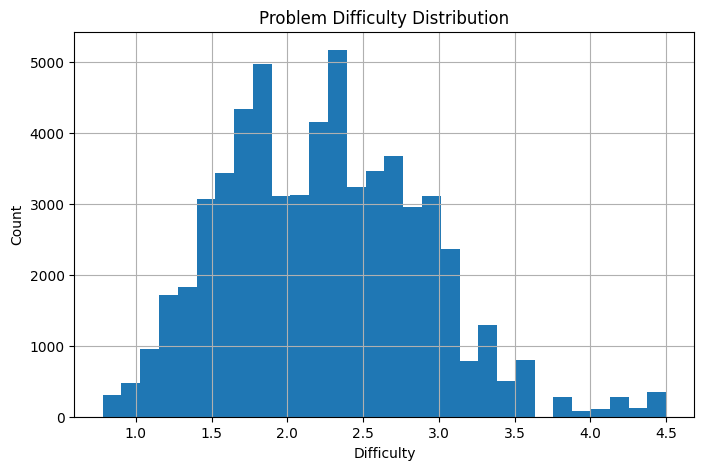

In [ ]:
plt.figure(figsize=(8,5))
df['difficulty'].hist(bins=30)
plt.title('Problem Difficulty Distribution')
plt.xlabel('Difficulty')
plt.ylabel('Count')
plt.show()

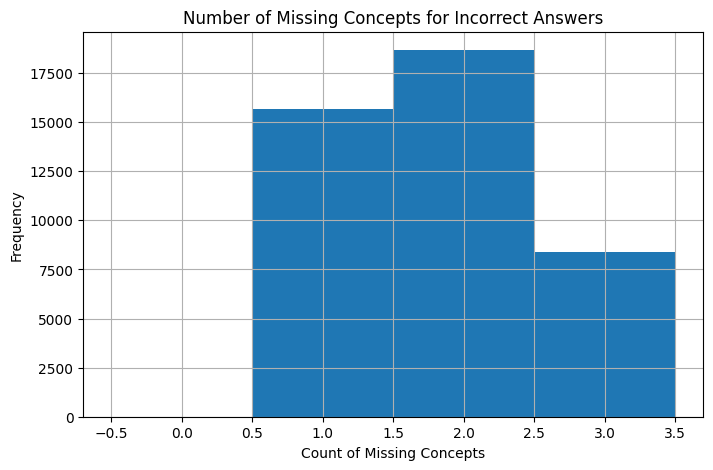

In [ ]:
plt.figure(figsize=(8,5))
incorrect_df = df[df['is_correct'] == 0]
incorrect_df['n_missing'].hist(bins=np.arange(-0.5, 4.5, 1))
plt.title('Number of Missing Concepts for Incorrect Answers')
plt.xlabel('Count of Missing Concepts')
plt.ylabel('Frequency')
plt.show()

In [ ]:
top_missing_counter = Counter()
for lst in incorrect_df['true_missing_concepts']:
    for c in lst:
      top_missing_counter[c] += 1

top_missing_df = pd.DataFrame(top_missing_counter.items(), columns=['concept', 'count']).sort_values('count', ascending=False)
top_missing_df.head(10)

,concept,count
1,ratios_proportions,10172
2,fractions,9802
0,integer_arithmetic,9756
8,percentages,7189
4,geometry_area,7067
6,algebraic_simplification,6905
3,decimals,5865
9,polynomials,5733
13,exponents,4228
7,linear_equations,3013


## 6. Prepare labels for supervised learning

We focus on incorrect answers, because those are the cases where concept diagnosis matters the most.

Targets:
- `top1_missing`
- `top2_missing`
- `top3_missing`

if a rank does not exist, we use a special label: `NONE`.

In [ ]:
train_df = df[df['is_correct'] == 0].copy().reset_index(drop=True)

def get_rank(lst, idx):
    return lst[idx] if len(lst) > idx else 'NONE'

train_df['top1_missing'] = train_df['true_missing_concepts'].apply(lambda x: get_rank(x, 0))
train_df['top2_missing'] = train_df['true_missing_concepts'].apply(lambda x: get_rank(x, 1))
train_df['top3_missing'] = train_df['true_missing_concepts'].apply(lambda x: get_rank(x, 2))
train_df[['true_missing_concepts', 'top1_missing', 'top2_missing', 'top3_missing']].head()

,true_missing_concepts,top1_missing,top2_missing,top3_missing
0,[integer_arithmetic],integer_arithmetic,NONE,NONE
1,[integer_arithmetic],integer_arithmetic,NONE,NONE
2,"[ratios_proportions, fractions, decimals]",ratios_proportions,fractions,decimals
3,[geometry_area],geometry_area,NONE,NONE
4,"[geometry_area, geometry_volume]",geometry_area,geometry_volume,NONE


## 7. Feature engineering

We use:
- numeric student and attempt history features
- problem metadata
- one-hot indicators for concepts required by the problem
- one-hot indicators for primary concepts


In [ ]:
def add_concept_indicator_columns(input_df):
    out = input_df.copy()
    for c in CONCEPTS:
        out[f'req__{c}'] = out['required_concepts'].apply(lambda x: int(c in x))
        out[f'prim__{c}'] = out['primary_concepts'].apply(lambda x: int(c in x))
    return out

model_df = add_concept_indicator_columns(train_df)

feature_cols_numeric = [
    'grade_level', 'study_hours_per_week', 'attendance_rate', 'confidence_trait',
    'carelessness', 'difficulty', 'num_primary_concepts', 'num_required_concepts',
    'hist_required_acc_mean', 'hist_primary_acc_mean',
    'hist_total_attempts_on_required', 'hist_total_attempts_on_primary',
    'answer_time_sec', 'pre_answer_confidence'
]

feature_cols_categorical = ['grade_band']
feature_cols_concepts = [c for c in model_df.columns if c.startswith('req__') or c.startswith('prim__')]

X = model_df[feature_cols_numeric + feature_cols_categorical + feature_cols_concepts]
y_top1 = model_df['top1_missing']
y_top2 = model_df['top2_missing']
y_top3 = model_df['top3_missing']

X_train, X_test, y1_train, y1_test, y2_train, y2_test, y3_train, y3_test = train_test_split(
    X, y_top1, y_top2, y_top3, test_size=0.2, random_state=SEED, stratify=y_top1
)

print(X_train.shape, X_test.shape)
print(y1_train.value_counts().head())

(34156, 43) (8539, 43)
top1_missing
percentages           4892
geometry_area         4688
ratios_proportions    4506
polynomials           3328
fractions             3099
Name: count, dtype: int64


## 8. Machine learning baseline

We train a **Random Forest** model for the top-1 missing concept.
Then we train a **multi-output** model for top-1, top-2, and top-3 together.

In [ ]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_cols_numeric),
        ('cat', 'passthrough', feature_cols_concepts),  # already numeric 0/1
        ('grade', 'passthrough', ['grade_band'])        # will handle below via get_dummies
    ],
    remainder='drop'
)

In [ ]:
# Simpler route: use pandas get_dummies for grade_band
X_train_enc = pd.get_dummies(X_train, columns=['grade_band'], drop_first=False)
X_test_enc = pd.get_dummies(X_test, columns=['grade_band'], drop_first=False)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

rf_top1 = RandomForestClassifier(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=-1
)
rf_top1.fit(X_train_enc, y1_train)

pred1 = rf_top1.predict(X_test_enc)
proba1 = rf_top1.predict_proba(X_test_enc)

acc1 = accuracy_score(y1_test, pred1)
print('Top-1 concept exact accuracy:', round(acc1, 4))
print('\nClassification report (top-1):')
print(classification_report(y1_test, pred1, zero_division=0))

Top-1 concept exact accuracy: 0.7242

Classification report (top-1):
                          precision    recall  f1-score   support

algebraic_simplification       0.82      0.61      0.70       773
     data_interpretation       0.00      0.00      0.00       108
                decimals       0.86      0.62      0.72       535
               exponents       0.82      0.66      0.73       430
               fractions       0.86      0.58      0.69       775
           geometry_area       0.75      0.95      0.84      1172
         geometry_volume       1.00      0.02      0.03       124
      integer_arithmetic       1.00      0.54      0.70       487
        linear_equations       0.55      0.65      0.59       325
             percentages       0.75      1.00      0.85      1223
             polynomials       0.69      0.78      0.73       832
      probability_basics       0.50      0.61      0.55       327
     quadratic_equations       0.52      0.71      0.60       302
      

## 9. Inspect model behavior on examples

In [ ]:
def show_predictions(n=10):
    sample_idx = np.random.choice(np.arange(len(X_test_enc)), size=n, replace=False)
    sample_raw = X_test.iloc[sample_idx].copy().reset_index(drop=True)
    sample_pred = rf_top1.predict(X_test_enc.iloc[sample_idx])
    sample_true = y1_test.iloc[sample_idx].reset_index(drop=True)

    out = sample_raw[['grade_level', 'grade_band', 'difficulty',
                      'num_primary_concepts', 'num_required_concepts',
                      'hist_primary_acc_mean', 'hist_required_acc_mean',
                      'pre_answer_confidence', 'answer_time_sec']].copy()
    out['true_top1_missing'] = sample_true
    out['pred_top1_missing'] = sample_pred
    return out

show_predictions(12)

,grade_level,grade_band,difficulty,num_primary_concepts,num_required_concepts,hist_primary_acc_mean,hist_required_acc_mean,pre_answer_confidence,answer_time_sec,true_top1_missing,pred_top1_missing
0,6,elementary,2.24,1,3,0.000000,0.040274,0.716,78.39,geometry_area,geometry_area
1,10,middle,2.29,1,5,-1.000000,0.125000,0.531,106.11,probability_basics,ratios_proportions
2,10,elementary,1.91,1,2,0.250000,0.230263,0.161,82.88,fractions,fractions
3,11,elementary,3.32,2,7,0.166667,0.294434,0.259,101.00,geometry_area,percentages
4,10,high,2.14,1,4,0.333333,0.403382,0.770,83.71,geometry_volume,geometry_area
5,7,high,3.52,2,7,0.043478,0.036813,0.660,118.45,polynomials,quadratic_equations
6,7,middle,1.23,1,2,0.055556,0.074289,0.276,83.30,algebraic_simplification,algebraic_simplification
7,5,high,2.04,1,4,0.111111,0.104861,0.640,87.40,decimals,ratios_proportions
8,6,middle,2.22,1,3,0.000000,0.093983,0.666,88.04,geometry_area,geometry_area
9,7,elementary,3.11,2,7,0.166667,0.178345,0.403,111.00,probability_basics,probability_basics


In [ ]:
# Feature importance for the top-1 missing concept model
importances = pd.Series(rf_top1.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
importances.head(20)

,0
num_required_concepts,0.065411
req__geometry_area,0.059317
req__percentages,0.058004
req__fractions,0.050187
req__decimals,0.047436
req__ratios_proportions,0.042679
difficulty,0.041123
req__algebraic_simplification,0.040436
study_hours_per_week,0.032571
req__exponents,0.031226


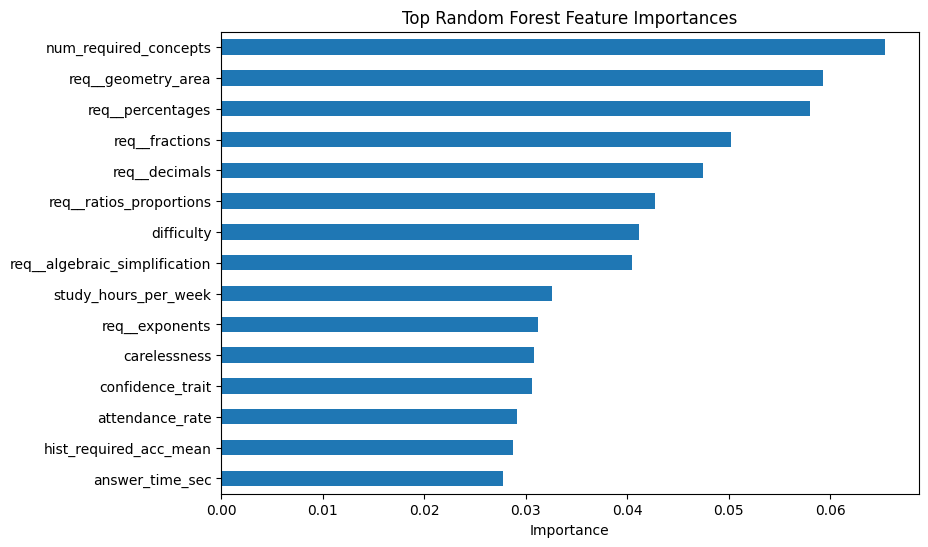

In [ ]:
plt.figure(figsize=(9,6))
importances.head(15).sort_values().plot(kind='barh')
plt.title('Top Random Forest Feature Importances')
plt.xlabel('Importance')
plt.show()

## 10. Deep learning model

We now create a **neural network** to predict a **multi-label concept gap vector**.

Instead of predicting only one concept, this network predicts which concepts should be reviewed.

This can later support:
- ranked recommendations
- threshold-based review suggestions
- personalilzed tutoring flows

In [ ]:
dl_df = train_df.copy()
mlb = MultiLabelBinarizer(classes=CONCEPTS)
Y_multi = mlb.fit_transform(dl_df['true_missing_concepts'])

X_dl = add_concept_indicator_columns(dl_df)[feature_cols_numeric + feature_cols_categorical + feature_cols_concepts]
X_dl_enc = pd.get_dummies(X_dl, columns=['grade_band'], drop_first=False)

X_dl_train, X_dl_test, Y_dl_train, Y_dl_test = train_test_split(
    X_dl_enc, Y_multi, test_size=0.2, random_state=SEED
)

scaler = StandardScaler()
X_dl_train_scaled = scaler.fit_transform(X_dl_train)
X_dl_test_scaled = scaler.transform(X_dl_test)

print(X_dl_train_scaled.shape, Y_dl_train.shape)

(34156, 45) (34156, 14)


In [ ]:
if TF_AVAILABLE:
    input_dim = X_dl_train_scaled.shape[1]
    output_dim = Y_dl_train.shape[1]

    dl_model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.25),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.20),
        layers.Dense(64, activation='relu'),
        layers.Dense(output_dim, activation='sigmoid')
    ])

    dl_model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history = dl_model.fit(
        X_dl_train_scaled, Y_dl_train,
        validation_split=0.15,
        epochs=12,
        batch_size=128,
        verbose=1
    )
else:
    print('Skipping deep learning section because TensorFlow is unavailable.')

Epoch 1/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3385 - loss: 0.1918 - val_accuracy: 0.3423 - val_loss: 0.1457
Epoch 2/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3351 - loss: 0.1478 - val_accuracy: 0.3499 - val_loss: 0.1428
Epoch 3/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3326 - loss: 0.1446 - val_accuracy: 0.3437 - val_loss: 0.1421
Epoch 4/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3372 - loss: 0.1429 - val_accuracy: 0.3569 - val_loss: 0.1419
Epoch 5/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3380 - loss: 0.1419 - val_accuracy: 0.3517 - val_loss: 0.1415
Epoch 6/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3372 - loss: 0.1411 - val_accuracy: 0.3599 - val_loss: 0.1416
Epoch 7/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3385 - loss: 0.1406 - val_accuracy: 0.3462 - val_loss: 0.1414
Epoch 8/12
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3372 - loss: 0.1403 - val_accuracy: 0

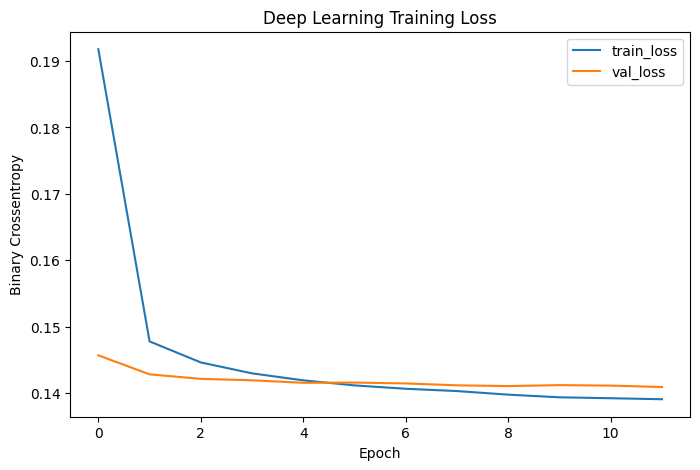

In [ ]:
if TF_AVAILABLE:
    plt.figure(figsize=(8,5))
    plt.plot(history.history['loss'], label='train_loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.title('Deep Learning Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Binary Crossentropy')
    plt.legend()
    plt.show()

In [ ]:
def multilabel_metrics(y_true, y_prob, threshold=0.35):
    y_pred = (y_prob >= threshold).astype(int)

    exact_match = np.mean(np.all(y_true == y_pred, axis=1))

    # micro precision/recall/f1
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)

    return {
        'exact_match_ratio': round(float(exact_match), 4),
        'micro_precision': round(float(precision), 4),
        'micro_recall': round(float(recall), 4),
        'micro_f1': round(float(f1), 4)
    }

if TF_AVAILABLE:
    Y_dl_prob = dl_model.predict(X_dl_test_scaled, verbose=0)
    metrics = multilabel_metrics(Y_dl_test, Y_dl_prob, threshold=0.35)
    print(metrics)

{'exact_match_ratio': 0.3094, 'micro_precision': 0.6625, 'micro_recall': 0.854, 'micro_f1': 0.7461}


In [ ]:
def rank_concepts_from_prob(prob_vector, topn=5):
    ranking = sorted(zip(CONCEPTS, prob_vector), key=lambda x: x[1], reverse=True)
    return ranking[:topn]

if TF_AVAILABLE:
    idx = np.random.randint(0, len(X_dl_test_scaled))
    print('True missing concepts:', [CONCEPTS[i] for i,v in enumerate(Y_dl_test[idx]) if v == 1])
    print('Predicted ranked concepts:')
    for c, p in rank_concepts_from_prob(Y_dl_prob[idx], topn=8):
        print(f'  {c:25s} {p:.3f}')

True missing concepts: ['decimals', 'linear_equations']
Predicted ranked concepts:
  linear_equations          0.627
  algebraic_simplification  0.553
  decimals                  0.504
  integer_arithmetic        0.192
  ratios_proportions        0.006
  exponents                 0.003
  fractions                 0.001
  probability_basics        0.001


## 11. Reinforcement learning style adaptive review demo

This product goal is not only to diagnose missing concepts, but also to decide:

> **Waht should the student review next?**

Here we build a simple **epsilon-greedy contextual review policy**:
- state: student mastery profile in the simulator
- action: recommend one concept to reviewe
- reward: improvement in correctness on future sampled problems

This is a lightweight RL demonstration suitable for a prototype.
For proeduction, we could later replace it with:
- contextual bandits
- Q-learning / DQN
- policy gradient methods
- knowledge tracing + tutoring policy optimization



In [ ]:
def simulate_review(student_mastery, concept, intensity=0.12):
    # reviewing a concept helps both the concept and some prerequisites slightly
    student_mastery = dict(student_mastery)
    student_mastery[concept] = float(np.clip(student_mastery[concept] + intensity, 0.01, 0.99))
    for p in PREREQS.get(concept, []):
        student_mastery[p] = float(np.clip(student_mastery[p] + 0.4*intensity, 0.01, 0.99))
    return student_mastery

def estimate_future_reward(student, concept, problem_bank, n_eval=12):
    # reward = post-review correctness rate - pre-review correctness rate
    base_mastery = student['mastery']
    improved_mastery = simulate_review(base_mastery, concept)

    def eval_rate(mastery_dict):
        temp_student = dict(student)
        temp_student['mastery'] = mastery_dict
        probs = []
        for _ in range(n_eval):
            problem = problem_bank.sample(1, random_state=np.random.randint(0, 10**6)).iloc[0]
            attempt = simulate_attempt(temp_student, problem)
            probs.append(attempt['prob_correct_latent'])
        return np.mean(probs)

    before = eval_rate(base_mastery)
    after = eval_rate(improved_mastery)
    return float(after - before)

def epsilon_greedy_recommend(student, q_values, epsilon=0.15):
    if np.random.rand() < epsilon:
        return random.choice(CONCEPTS)
    return max(q_values, key=q_values.get)

def train_bandit_policy(students_subset, problem_bank, episodes=250):
    q_values = {c: 0.0 for c in CONCEPTS}
    counts = {c: 0 for c in CONCEPTS}

    reward_history = []

    for ep in range(episodes):
        student = random.choice(students_subset)
        action = epsilon_greedy_recommend(student, q_values, epsilon=0.20)
        reward = estimate_future_reward(student, action, problem_bank, n_eval=10)

        counts[action] += 1
        q_values[action] += (reward - q_values[action]) / counts[action]
        reward_history.append(reward)

    return q_values, counts, reward_history

bandit_q, bandit_counts, reward_history = train_bandit_policy(students[:150], problem_bank, episodes=300)
sorted(bandit_q.items(), key=lambda x: x[1], reverse=True)[:10]

[('geometry_area', 0.020659883219088793),
 ('fractions', 0.014667797552785293),
 ('decimals', 0.013368406361005308),
 ('exponents', 0.012826306624688918),
 ('data_interpretation', 0.011494326944633676),
 ('ratios_proportions', 0.01140022711461996),
 ('linear_equations', 0.009291014767050585),
 ('integer_arithmetic', 0.00732882221017153),
 ('polynomials', 0.006269234555921786),
 ('quadratic_equations', 0.00431766061916182)]

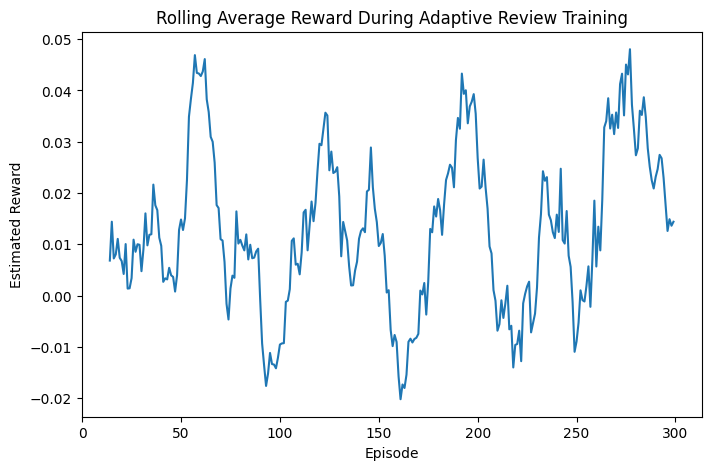

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(pd.Series(reward_history).rolling(15).mean())
plt.title("Rolling Average Reward During Adaptive Review Training")
plt.xlabel("Episode")
plt.ylabel("Estimated Reward")
plt.show()

In [ ]:
bandit_summary = pd.DataFrame({
    'concept': list(bandit_q.keys()),
    'estimated_reward': list(bandit_q.values()),
    'times_selected': [bandit_counts[c] for c in bandit_q.keys()]
}).sort_values(['estimated_reward', 'times_selected'], ascending=False)

bandit_summary.head(15)

,concept,estimated_reward,times_selected
10,geometry_area,0.020660,82
1,fractions,0.014668,24
2,decimals,0.013368,9
7,exponents,0.012826,128
13,data_interpretation,0.011494,1
3,ratios_proportions,0.011400,4
6,linear_equations,0.009291,10
0,integer_arithmetic,0.007329,6
8,polynomials,0.006269,6
9,quadratic_equations,0.004318,3


## 12. Inference function for the future App

This function below is the core prototype interface.

Given a student attempt record, it returns:
- ranked missing concepts
- top 3 concepts to review
- prediction confidence proxies

In [ ]:
def build_rf_ranked_prediction(row_like):
    row_df = pd.DataFrame([row_like])
    # The line below caused the error as row_like already has the indicator columns
    # row_df = add_concept_indicator_columns(row_df)

    # Select only the relevant feature columns, which already include the concept indicators
    row_df = row_df[feature_cols_numeric + feature_cols_categorical + feature_cols_concepts]
    row_df = pd.get_dummies(row_df, columns=['grade_band'], drop_first=False)
    row_df = row_df.reindex(columns=X_train_enc.columns, fill_value=0)

    probs = rf_top1.predict_proba(row_df)[0]
    ranked = sorted(zip(rf_top1.classes_, probs), key=lambda x: x[1], reverse=True)
    return ranked

def app_diagnose_missing_concepts(example_row, topn=5):
    ranked_top1 = build_rf_ranked_prediction(example_row)
    ranked_concepts = [(c, float(p)) for c, p in ranked_top1 if c != 'NONE'][:topn]
    return {
        'predicted_top_missing_concepts': ranked_concepts[:3],
        'extended_ranked_list': ranked_concepts
    }

In [ ]:
# demo inference on a held-out incorrect answer
demo_row = X_test.iloc[0].to_dict()
diagnosis = app_diagnose_missing_concepts(demo_row, topn=8)
diagnosis


{'predicted_top_missing_concepts': [('ratios_proportions', 0.4380271395858316),
  ('probability_basics', 0.3727775418959604),
  ('decimals', 0.09961997301727653)],
 'extended_ranked_list': [('ratios_proportions', 0.4380271395858316),
  ('probability_basics', 0.3727775418959604),
  ('decimals', 0.09961997301727653),
  ('fractions', 0.07666124761907903),
  ('integer_arithmetic', 0.009818861764036674),
  ('algebraic_simplification', 0.0012568882569611),
  ('exponents', 0.0011594497739364938),
  ('linear_equations', 0.000362633979909628)]}

## 13. Combine diagnosis + review recommendation

This demonstrates how the App can:
1. diagnose likely concept gaps
2. recommend a next concept for review
3. later adapt using a tutoring policy

In [ ]:
def recommend_next_review_concept(example_row, bandit_q_values):
    diag = app_diagnose_missing_concepts(example_row, topn=5)
    candidates = [c for c, _ in diag['extended_ranked_list']]
    if len(candidates) == 0:
        return None, diag

    best = max(candidates, key=lambda c: bandit_q_values.get(c, 0.0))
    return best, diag

next_review, diag = recommend_next_review_concept(demo_row, bandit_q)
print('Recommended next review concept:', next_review)
print('Predicted ranked gaps:', diag['predicted_top_missing_concepts'])


Recommended next review concept: fractions
Predicted ranked gaps: [('ratios_proportions', 0.4380271395858316), ('probability_basics', 0.3727775418959604), ('decimals', 0.09961997301727653)]


## 14. Save artifacts for later web or App packaging

We export:
- synthetic datasets
- trained model-ready tables

Later, when our package into a web App or iOS backend, we can additionaly save:
- trained sklearn models with `joblib`
- neural network with `model.save(...)`
- concept metadata as JSON

In [ ]:
# Save example outputs
output_train_csv = 'synthetic_math_concept_gap_dataset.csv'
output_problem_csv = 'synthetic_problem_bank.csv'

train_df.to_csv(output_train_csv, index=False)
problem_bank.to_csv(output_problem_csv, index=False)

print('Saved:', output_train_csv)
print('Saved:', output_problem_csv)


Saved: synthetic_math_concept_gap_dataset.csv
Saved: synthetic_problem_bank.csv


## 15. What to do next after this prototype

### Good next steps:
1. Replace synthetic problem bank with your real math problem inventory
2. Build a concept tagging layer for each problem
3. Collect real student responses
4. Train with real ovservable features
5. Add an App layer:
    - **web**: Streamlit / FastAPI/ react frontend
    - **mobile / iOS style**: Flutter / React Native / Swift frontend + Python API backend
6. Upgrade the learning policy:
    - contextual bandits
    - Bayesian knowledge tracing
    - deep knowledge tracing
    - reinforcement learning for adaptive tutoring